In [2]:
import pickle
import numpy as np
import matplotlib.pyplot as plt



# Generación de la data

In [7]:
!wget https://data.mendeley.com/public-files/datasets/7dybx7wyfn/files/854dd691-aad3-4793-af3b-6142d1ec8a2a/file_downloaded -O dataset_ecg.zip

--2026-02-07 03:37:02--  https://data.mendeley.com/public-files/datasets/7dybx7wyfn/files/854dd691-aad3-4793-af3b-6142d1ec8a2a/file_downloaded
Resolving data.mendeley.com (data.mendeley.com)... 162.159.130.86, 162.159.133.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.130.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/503a174a-a723-4aaa-86f2-9483e7412a77 [following]
--2026-02-07 03:37:02--  https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/503a174a-a723-4aaa-86f2-9483e7412a77
Resolving prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)... 3.5.66.5, 3.5.64.199, 3.5.69.44, ...
Connecting to prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)|3.5.66.5|:443... connected

In [8]:
!unzip dataset_ecg.zip -d ./RAW_ECG_DATASET

Archive:  dataset_ecg.zip
   creating: ./RAW_ECG_DATASET/MLII/
   creating: ./RAW_ECG_DATASET/MLII/1 NSR/
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (0).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (1).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (2).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (3).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (4).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (5).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (6).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (7).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (8).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/100m (9).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/101m (0).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/101m (1).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/101m (10).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/101m (2).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 NSR/101m (3).mat  
  inflating: ./RAW_ECG_DATASET/MLII/1 

In [9]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
from scipy.io import loadmat

In [11]:
!pwd

/content


In [12]:
path_root  = "/content"

In [10]:
path_db = "RAW_ECG_DATASET/MLII/"

In [13]:
list_path = sorted(os.listdir(os.path.join(path_root, path_db)))
list_path

['1 NSR',
 '10 VT',
 '11 IVR',
 '12 VFL',
 '13 Fusion',
 '14 LBBBB',
 '15 RBBBB',
 '16 SDHB',
 '17 PR',
 '2 APB',
 '3 AFL',
 '4 AFIB',
 '5 SVTA',
 '6 WPW',
 '7 PVC',
 '8 Bigeminy',
 '9 Trigeminy']

In [14]:
def extract_label(text):
    return re.findall(r'(\d+)\s+(.*)', text)[0][1]

extract_label("16 SDHB")

'SDHB'

In [15]:
def load_ecg_data(file_list):
    data = []
    for file in file_list:
        mat_data = loadmat(file)
        data.append(mat_data['val'][0])
    return np.array(data)

In [16]:
dict_labels = {}
for i in range(len(list_path)):
    #print(i, extract_label(list_path[i]))
    label = extract_label(list_path[i])
    data_aux = os.listdir(os.path.join(path_root, path_db,list_path[i]))
    data_aux = list(map(lambda x: os.path.join(path_root, path_db,list_path[i],x), data_aux))
    #print(data_aux[:3])
    dict_labels[label] = load_ecg_data(data_aux)

dict_labels

{'NSR': array([[1024, 1022, 1024, ..., 1018, 1015, 1010],
        [ 875,  874,  873, ...,  906,  906,  907],
        [ 839,  839,  839, ...,  917,  920,  920],
        ...,
        [1014, 1016, 1017, ..., 1027, 1027, 1033],
        [ 858,  860,  858, ...,  866,  866,  872],
        [ 990,  989,  986, ...,  990,  993,  995]], dtype=int16),
 'VT': array([[1238, 1216, 1191, ...,  988,  990,  991],
        [ 962,  961,  960, ...,  911,  914,  913],
        [ 865,  868,  873, ..., 1093, 1097, 1101],
        ...,
        [ 957,  963,  969, ...,  925,  925,  925],
        [ 880,  882,  884, ..., 1266, 1265, 1254],
        [ 930,  929,  928, ...,  937,  941,  948]], dtype=int16),
 'IVR': array([[1142, 1144, 1131, ...,  977,  977,  976],
        [1005, 1004, 1003, ...,  973,  972,  972],
        [1017, 1019, 1019, ..., 1066, 1073, 1085],
        ...,
        [ 971,  971,  974, ...,  998,  997,  998],
        [ 999, 1000, 1001, ..., 1042, 1048, 1051],
        [ 990,  991,  988, ..., 1009, 1012, 

In [17]:
print(dict_labels.keys())
print("n clases:",len(dict_labels))

dict_keys(['NSR', 'VT', 'IVR', 'VFL', 'Fusion', 'LBBBB', 'RBBBB', 'SDHB', 'PR', 'APB', 'AFL', 'AFIB', 'SVTA', 'WPW', 'PVC', 'Bigeminy', 'Trigeminy'])
n clases: 17


In [18]:
import pickle

with open('dict_labels.pkl', 'wb') as f:
    pickle.dump(dict_labels, f)

#  Graficamos una señal de ejemplo por cada clase

In [24]:
import os

os.mkdir("resultados/imagenes")

Señales de DATABASE



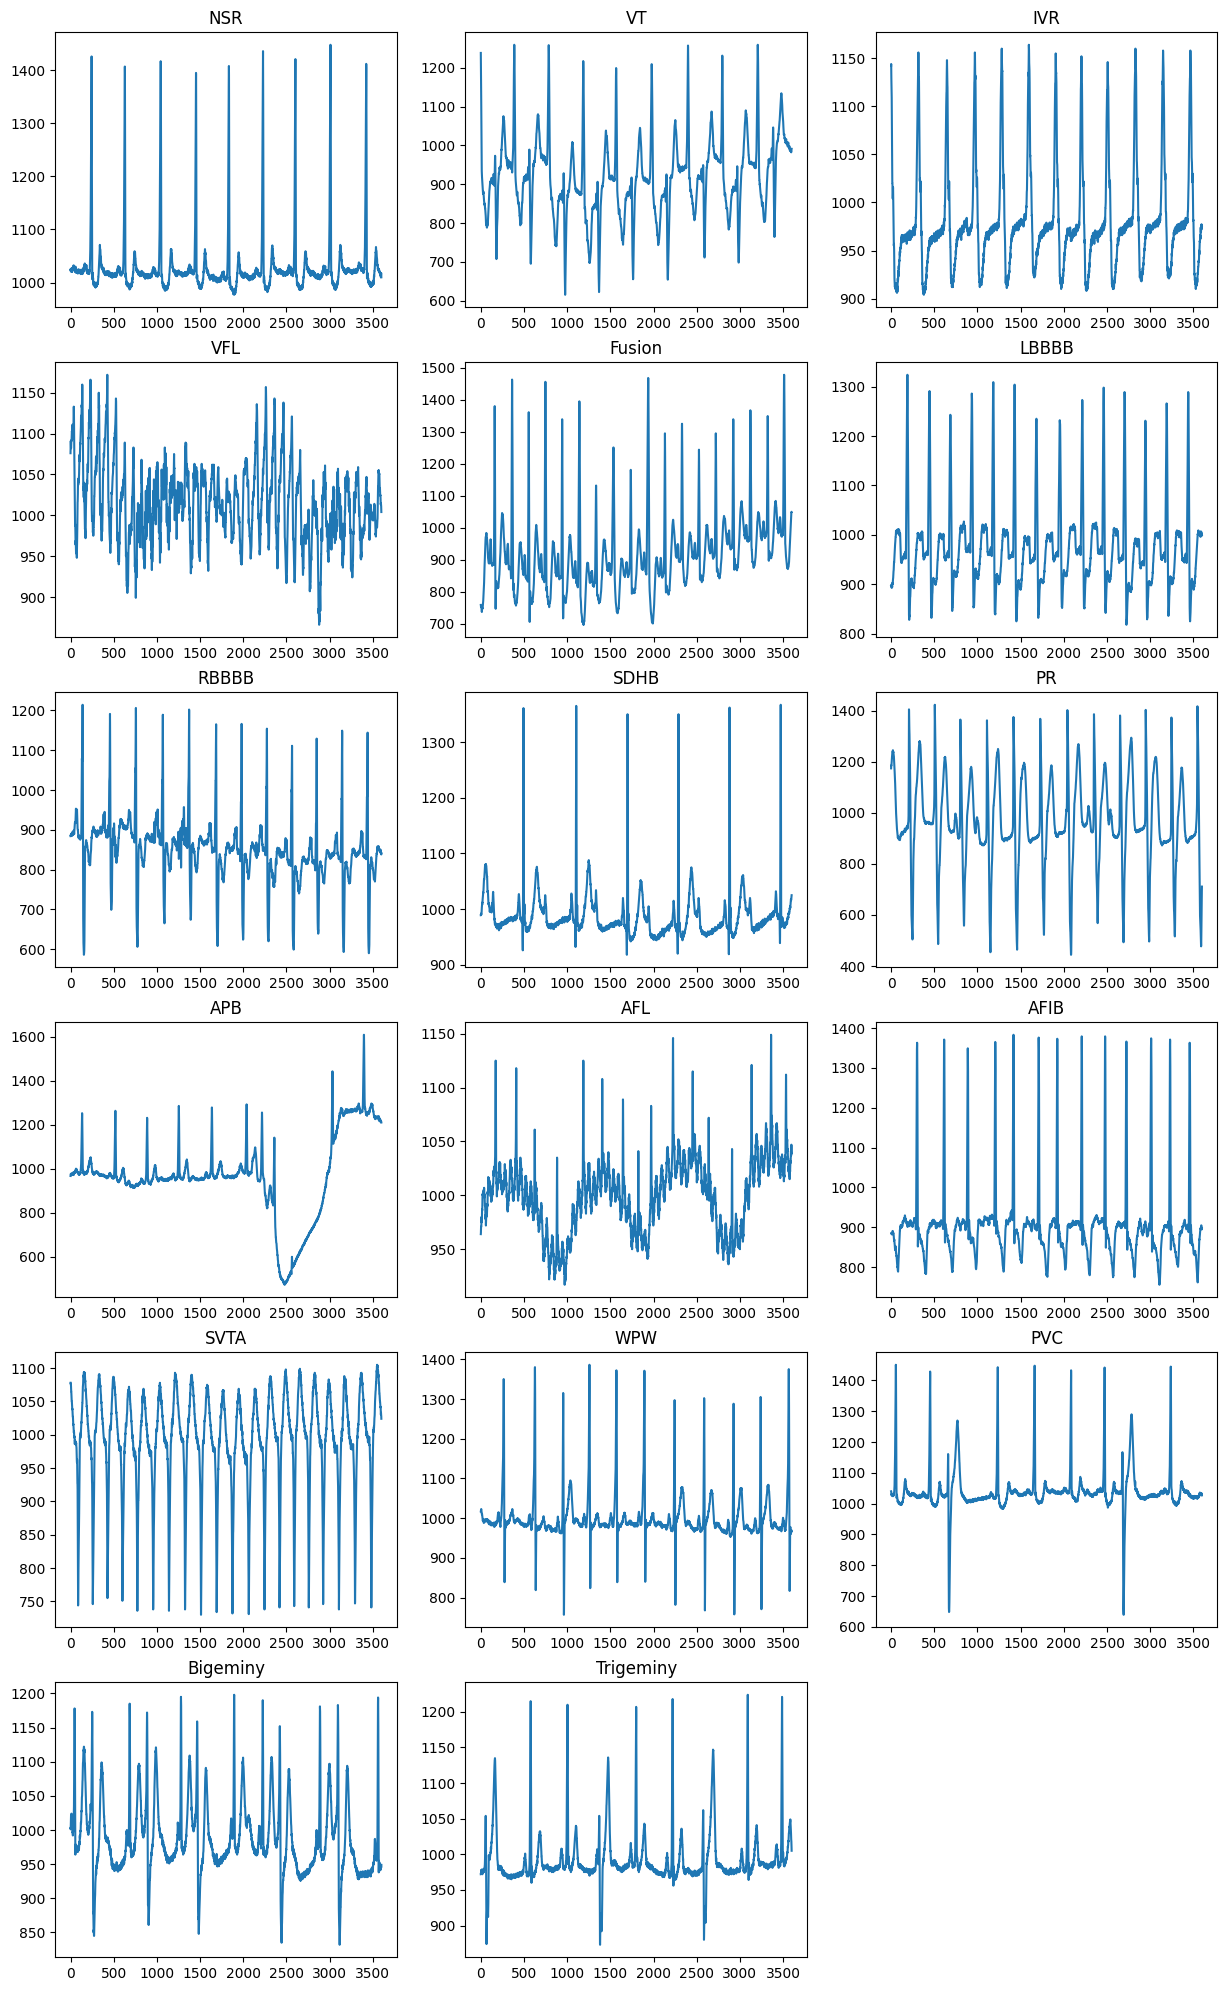

<Figure size 640x480 with 0 Axes>

In [25]:
pos = 0

plt.figure(figsize=(15,25))
#plt.suptitle()
print("Señales de DATABASE\n")
#plt.tight_layout(pad=10.0, h_pad=10.0, w_pad=20.0)

for i, name in enumerate(dict_labels.keys()):
    plt.subplot(6,3,i+1)
    plt.plot(dict_labels[name][pos])
    plt.title(name)

plt.show()
plt.savefig('./resultados/imagenes/ecg_dominio_tiempo.png')

FFT de DATABASE



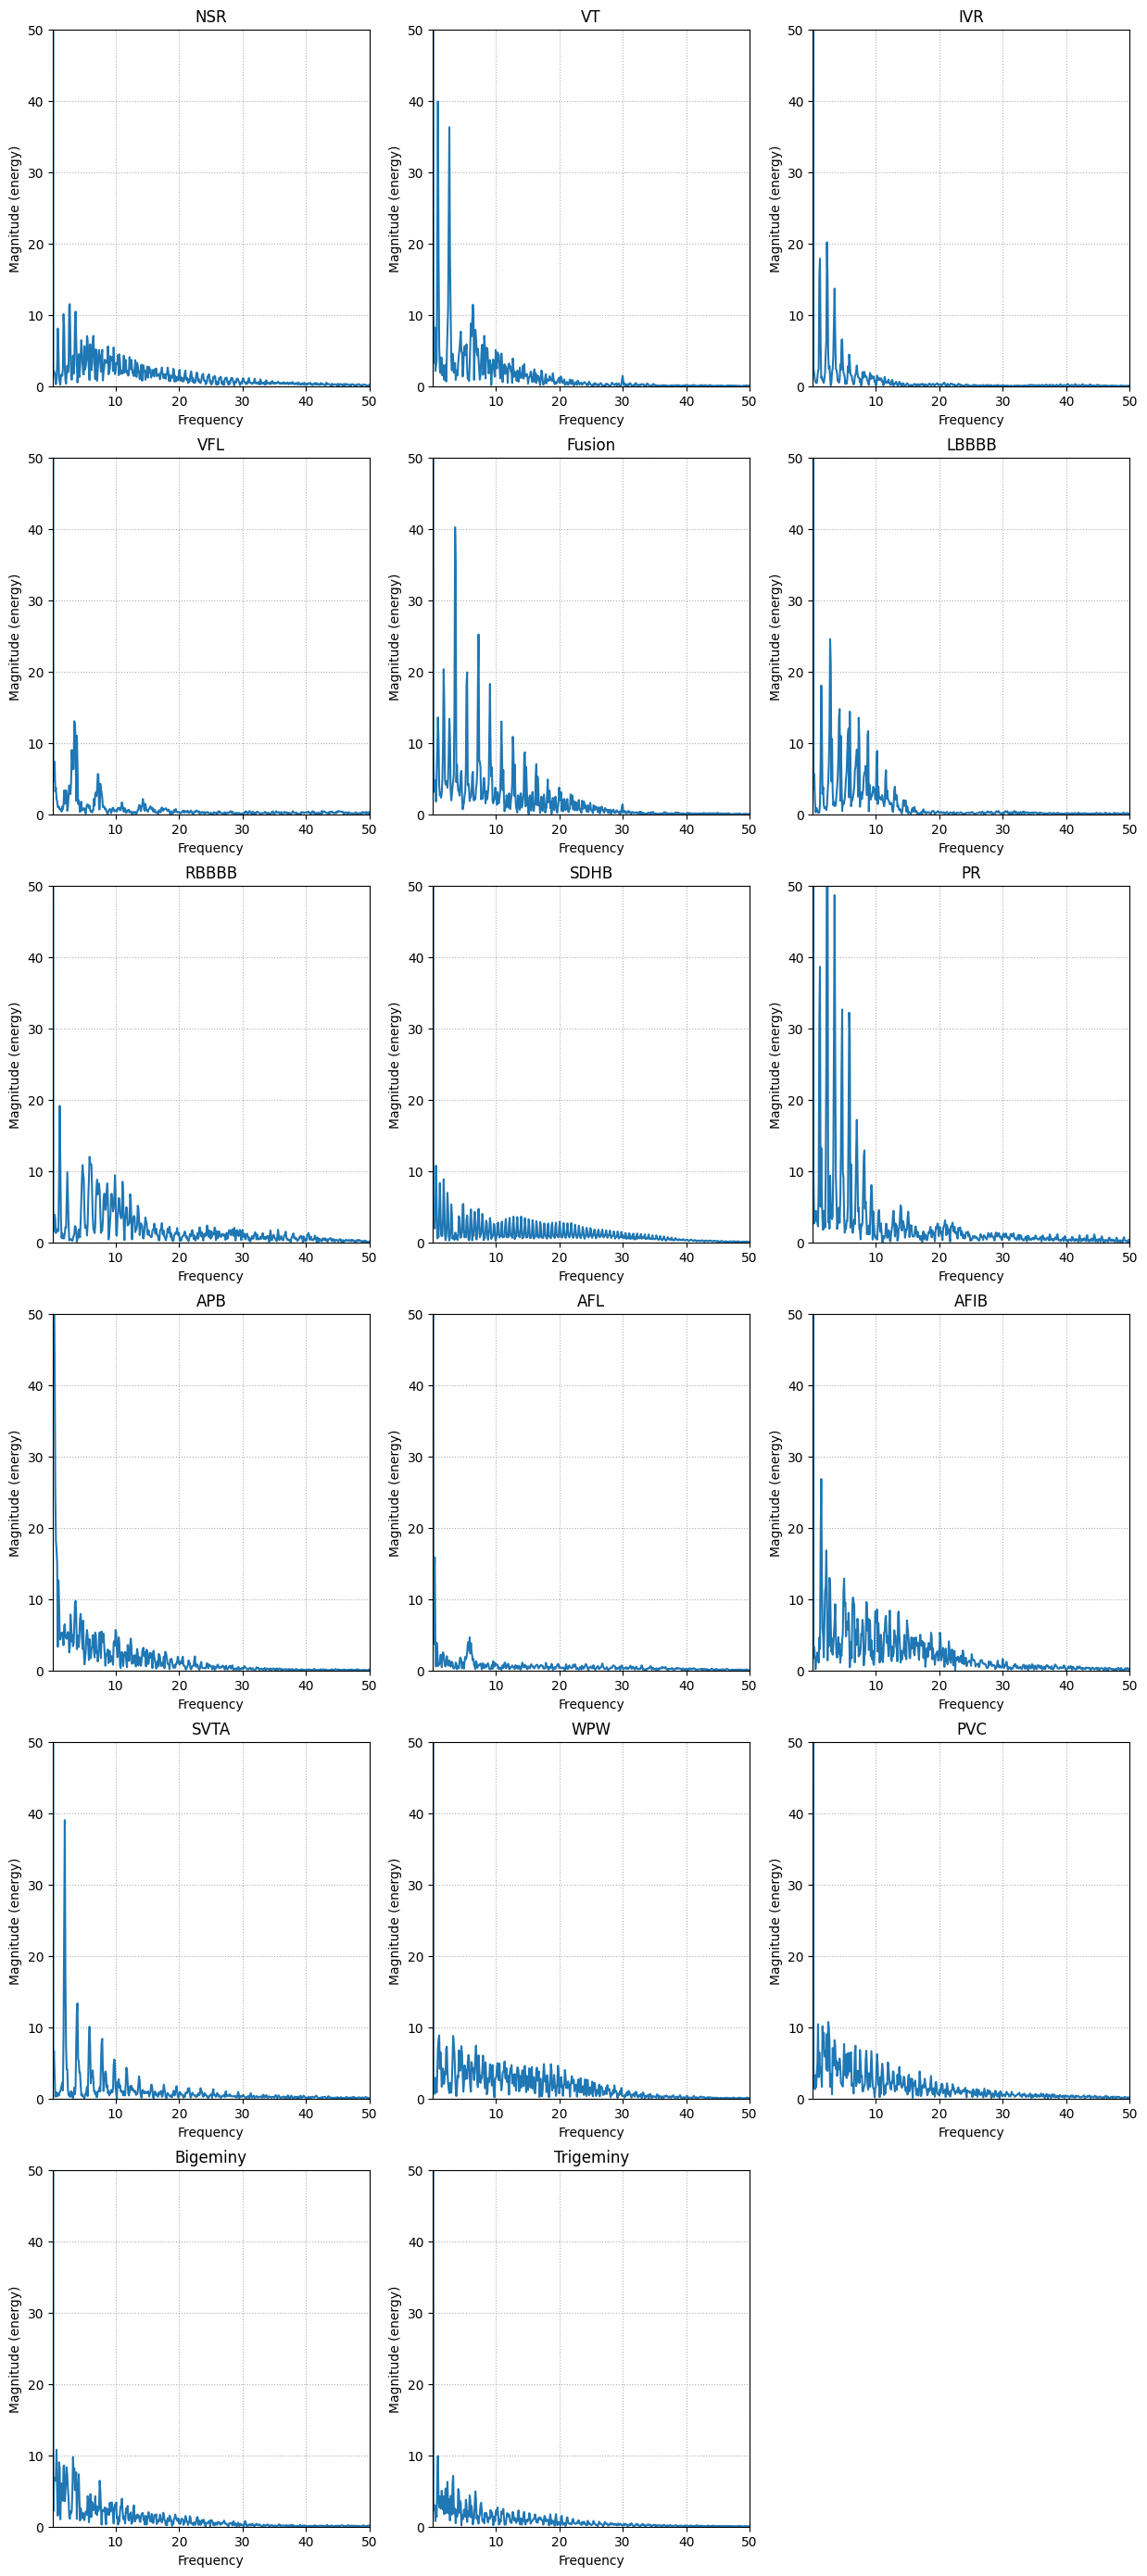

<Figure size 640x480 with 0 Axes>

In [26]:
pos = 0
fs = 360

plt.figure(figsize=(15,35))
print("FFT de DATABASE\n")
#plt.tight_layout()

for i, name in enumerate(dict_labels.keys()):
    plt.subplot(6,3,i+1)
    #plt.plot(dict_labels[name][pos])
    plt.magnitude_spectrum(dict_labels[name][pos], Fs=fs, color='C0')
    plt.xlim(0.1, 50)
    plt.ylim(0, 50)
    plt.grid(ls=":")
    #plt.axhline(0, color='black', lw=0.5)
    plt.title(name)

plt.show()
plt.savefig('./resultados/imagenes/ecg_dominio_frecuencia.png')


STFT de DATABASE



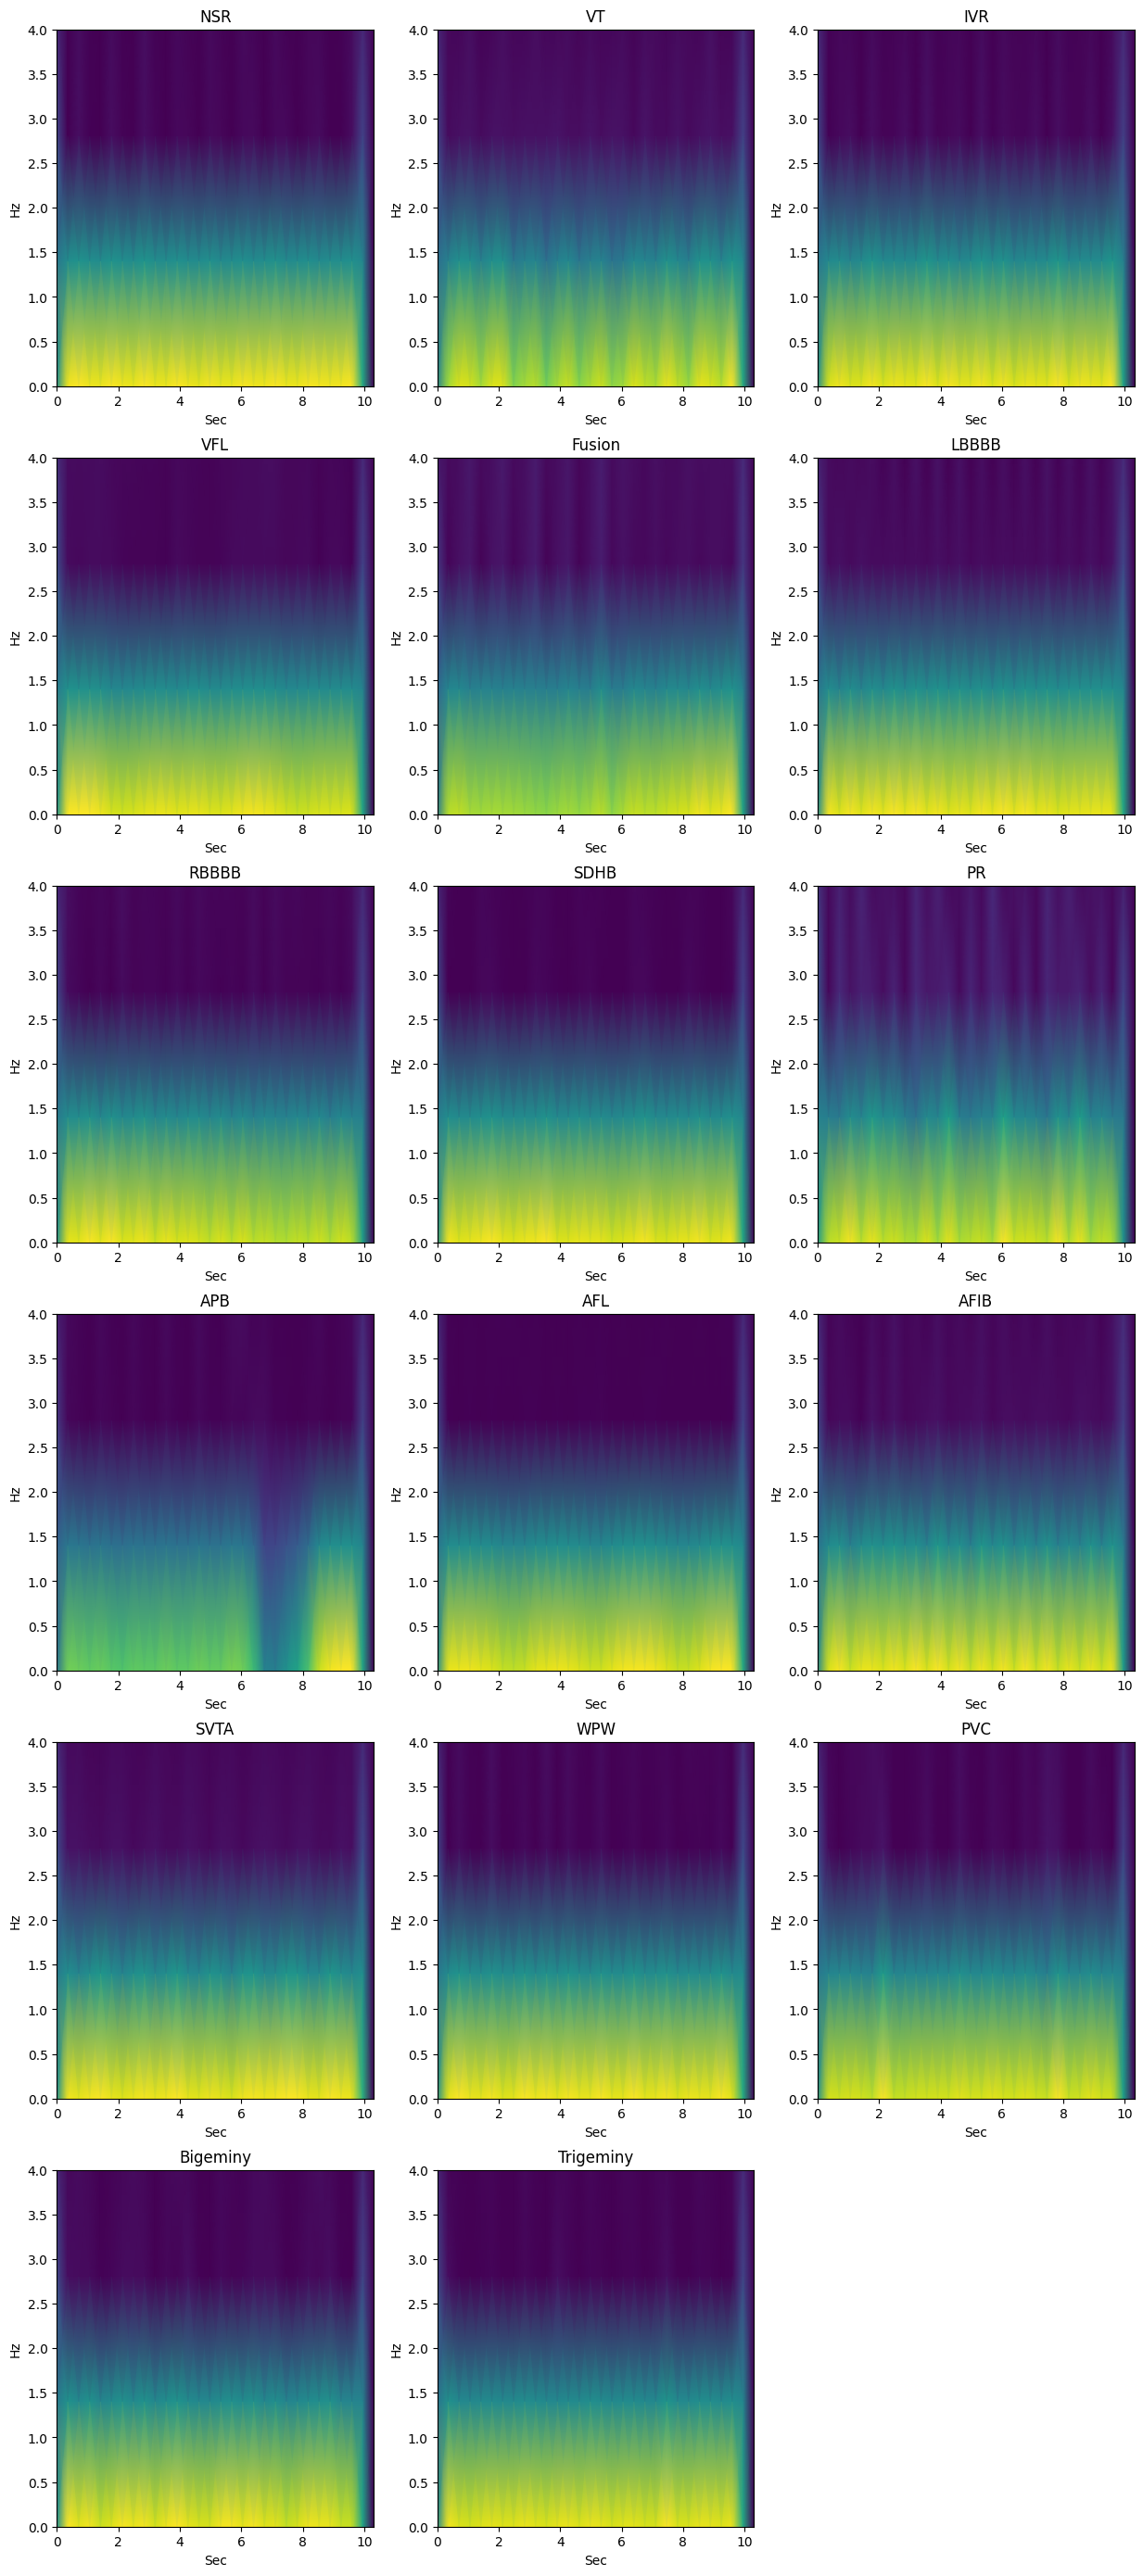

<Figure size 640x480 with 0 Axes>

In [27]:
from scipy.signal import stft

pos = 0
fs = 360

plt.figure(figsize=(15,35))
print("STFT de DATABASE\n")
#plt.tight_layout()

for i, name in enumerate(dict_labels.keys()):
    plt.subplot(6,3,i+1)
    #plt.plot(dict_labels[name][pos])
    #plt.magnitude_spectrum(dict_labels[name][pos], Fs=fs, color='C0')
    #plt.xlim(0.1, 50)
    #plt.ylim(0, 50)
    #plt.grid(ls=":")
    #plt.axhline(0, color='black', lw=0.5)
    x = dict_labels[name][pos]
    f, t, Zxx = stft(x, fs=fs, nperseg=256)

    plt.pcolormesh(t, f, np.abs(Zxx), shading='gouraud')
    plt.ylabel('Hz')
    plt.xlabel('Sec')
    plt.ylim(0, 4)
    plt.title(name)

plt.show()
plt.savefig('./resultados/imagenes/ecg_sftf.png')

In [28]:
dict_bar = {}
for i, name in enumerate(dict_labels.keys()):
    dict_bar[name] = len(dict_labels[name])
dict_bar

{'NSR': 283,
 'VT': 10,
 'IVR': 10,
 'VFL': 10,
 'Fusion': 11,
 'LBBBB': 103,
 'RBBBB': 62,
 'SDHB': 10,
 'PR': 45,
 'APB': 66,
 'AFL': 20,
 'AFIB': 135,
 'SVTA': 13,
 'WPW': 21,
 'PVC': 133,
 'Bigeminy': 55,
 'Trigeminy': 13}

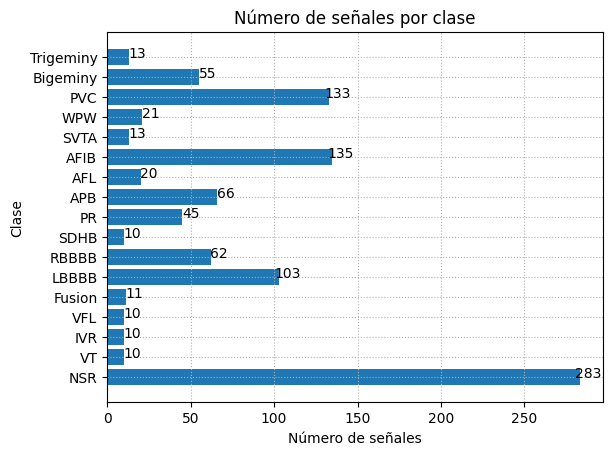

<Figure size 640x480 with 0 Axes>

In [29]:
plt.barh(dict_bar.keys(), dict_bar.values())
plt.yticks(rotation=0)
plt.grid(ls=":")
plt.title("Número de señales por clase")
plt.xlabel("Número de señales")
plt.ylabel("Clase")

for i, value in enumerate(dict_bar.values()):
    plt.text(value + 5, i, str(value), ha='center') # Added text labels on top of bars
plt.show()
plt.savefig('./resultados/imagenes/ecg_clases_barra.png')

# Tratamiento de señales

In [30]:
with open('dict_labels.pkl', 'rb') as f:
    dict_labels = pickle.load(f)
dict_labels

{'NSR': array([[1024, 1022, 1024, ..., 1018, 1015, 1010],
        [ 875,  874,  873, ...,  906,  906,  907],
        [ 839,  839,  839, ...,  917,  920,  920],
        ...,
        [1014, 1016, 1017, ..., 1027, 1027, 1033],
        [ 858,  860,  858, ...,  866,  866,  872],
        [ 990,  989,  986, ...,  990,  993,  995]], dtype=int16),
 'VT': array([[1238, 1216, 1191, ...,  988,  990,  991],
        [ 962,  961,  960, ...,  911,  914,  913],
        [ 865,  868,  873, ..., 1093, 1097, 1101],
        ...,
        [ 957,  963,  969, ...,  925,  925,  925],
        [ 880,  882,  884, ..., 1266, 1265, 1254],
        [ 930,  929,  928, ...,  937,  941,  948]], dtype=int16),
 'IVR': array([[1142, 1144, 1131, ...,  977,  977,  976],
        [1005, 1004, 1003, ...,  973,  972,  972],
        [1017, 1019, 1019, ..., 1066, 1073, 1085],
        ...,
        [ 971,  971,  974, ...,  998,  997,  998],
        [ 999, 1000, 1001, ..., 1042, 1048, 1051],
        [ 990,  991,  988, ..., 1009, 1012, 

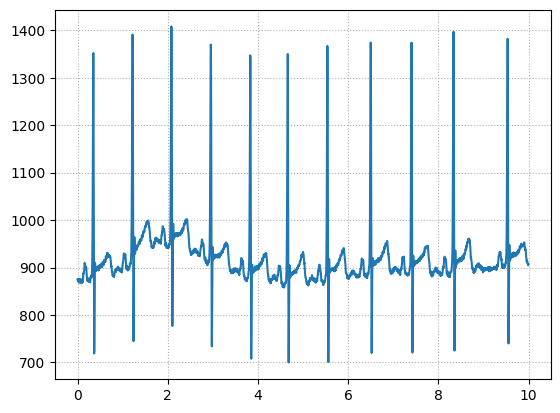

In [46]:
nsr = dict_labels["NSR"][1]

t = np.arange(len(nsr))/360


plt.plot(t, nsr)
plt.grid(ls=":")
plt.show()

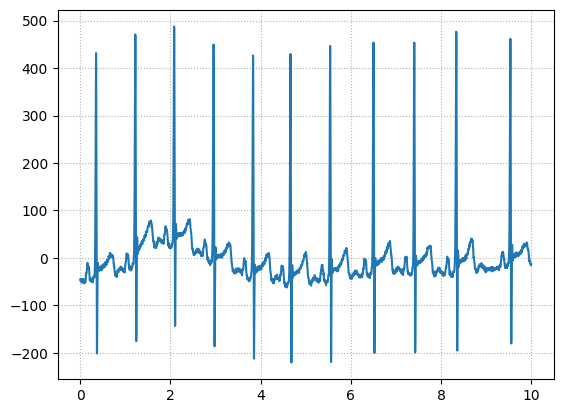

In [65]:
nsr = nsr - np.mean(nsr)
plt.plot(t, nsr)
plt.grid(ls=":")
plt.show()

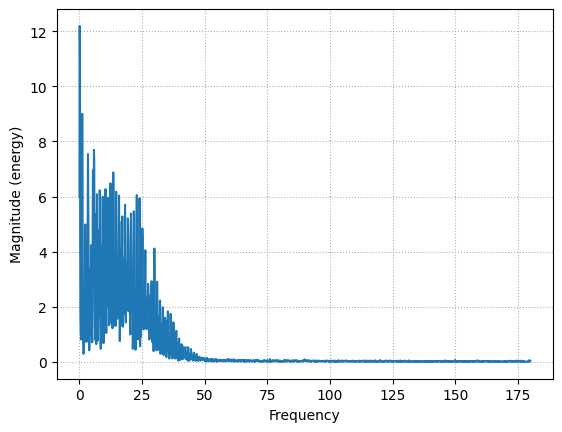

In [66]:
plt.magnitude_spectrum(nsr, Fs=360, color='C0')
plt.grid(ls=":")
plt.show()

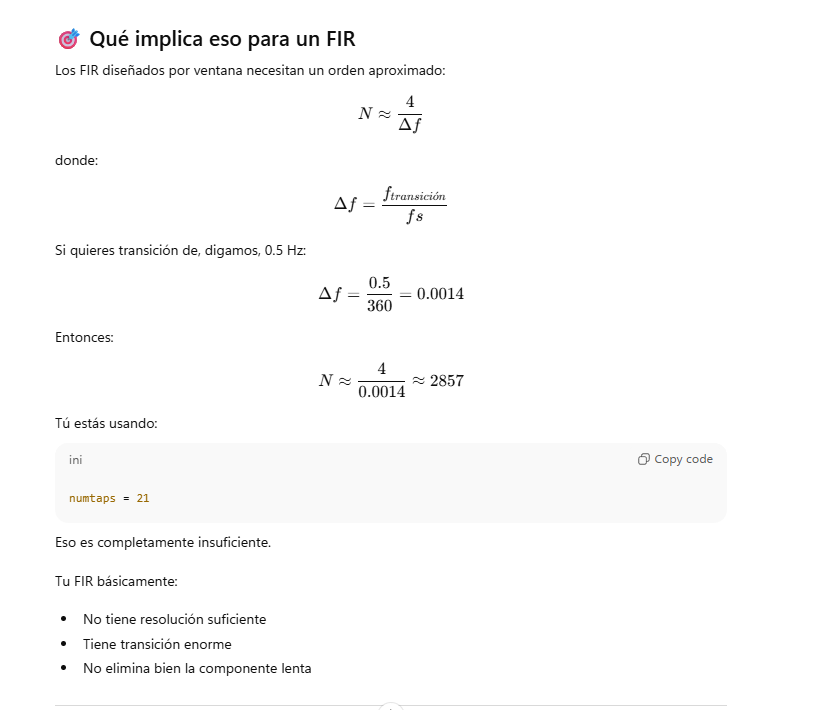

Por qué el wandering es especial

El baseline wandering está muy cerca de DC.

Y los FIR tienen un problema estructural:

Cuanto más cerca de DC quieres cortar,
más largo debe ser el filtro.

Es una limitación matemática fundamental.




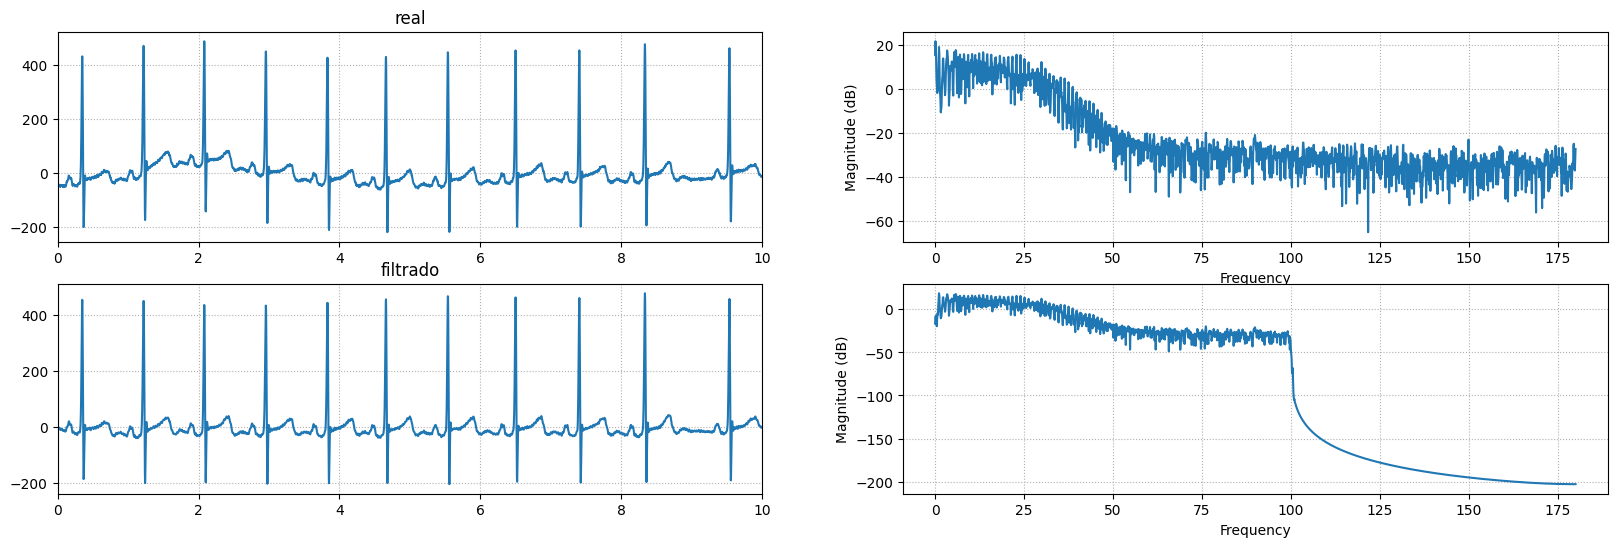

In [95]:
from scipy  import signal

fs = 360

b = signal.firwin(numtaps=801, cutoff=[0.5,100], window='hann', fs=360,  pass_zero=False)

y = signal.filtfilt(b, 1, nsr)

plt.figure(figsize=(20,6))

plt.subplot(2,2,1)
plt.title("real")
plt.plot(t,nsr)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,2)
plt.magnitude_spectrum(nsr, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.subplot(2,2,3)
plt.title("filtrado")
plt.plot(t,y)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,4)
plt.magnitude_spectrum(y, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.show()

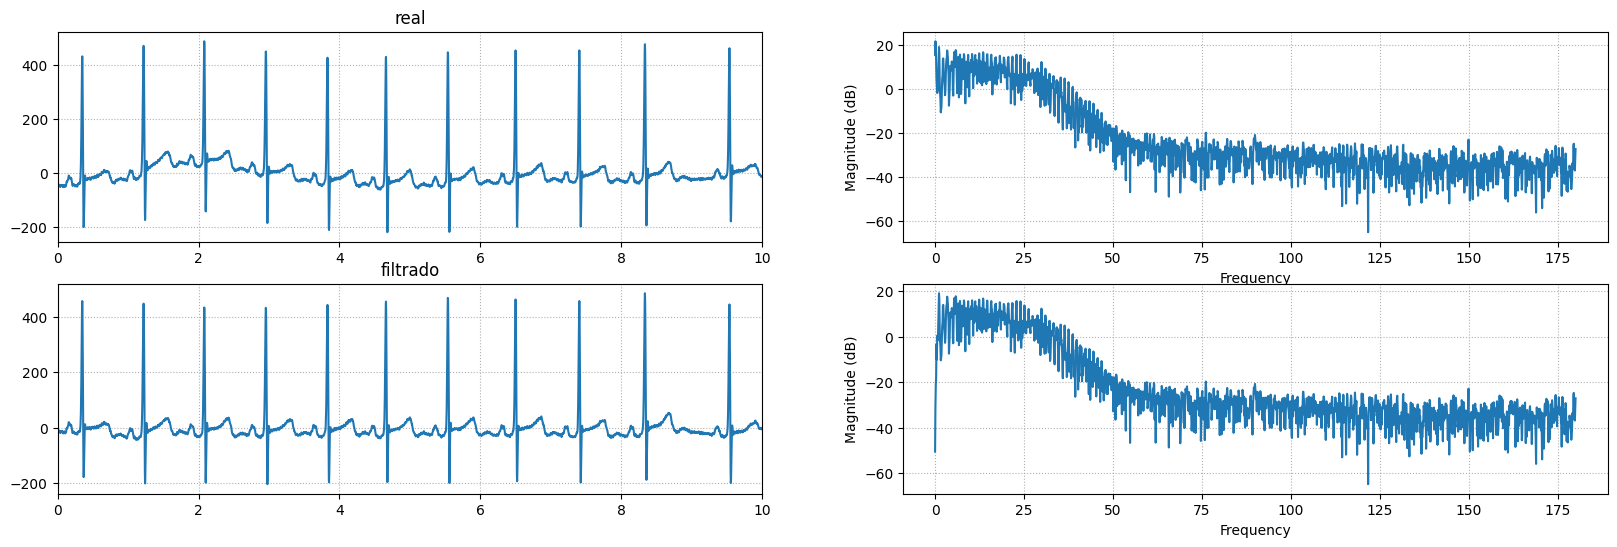

In [94]:
sos = signal.butter(4, 0.5,
                    btype='high',
                    fs=fs,
                    output='sos')

y = signal.sosfiltfilt(sos, nsr)

plt.figure(figsize=(20,6))

plt.subplot(2,2,1)
plt.title("real")
plt.plot(t,nsr)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,2)
plt.magnitude_spectrum(nsr, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.subplot(2,2,3)
plt.title("filtrado")
plt.plot(t,y)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,4)
plt.magnitude_spectrum(y, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.show()


## Señal 2

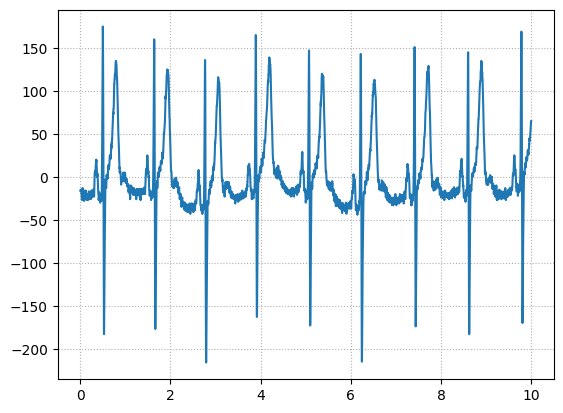

In [97]:
nsr = dict_labels["NSR"][2]

t = np.arange(len(nsr))/360
nsr = nsr - np.mean(nsr)

plt.plot(t, nsr)
plt.grid(ls=":")
plt.show()

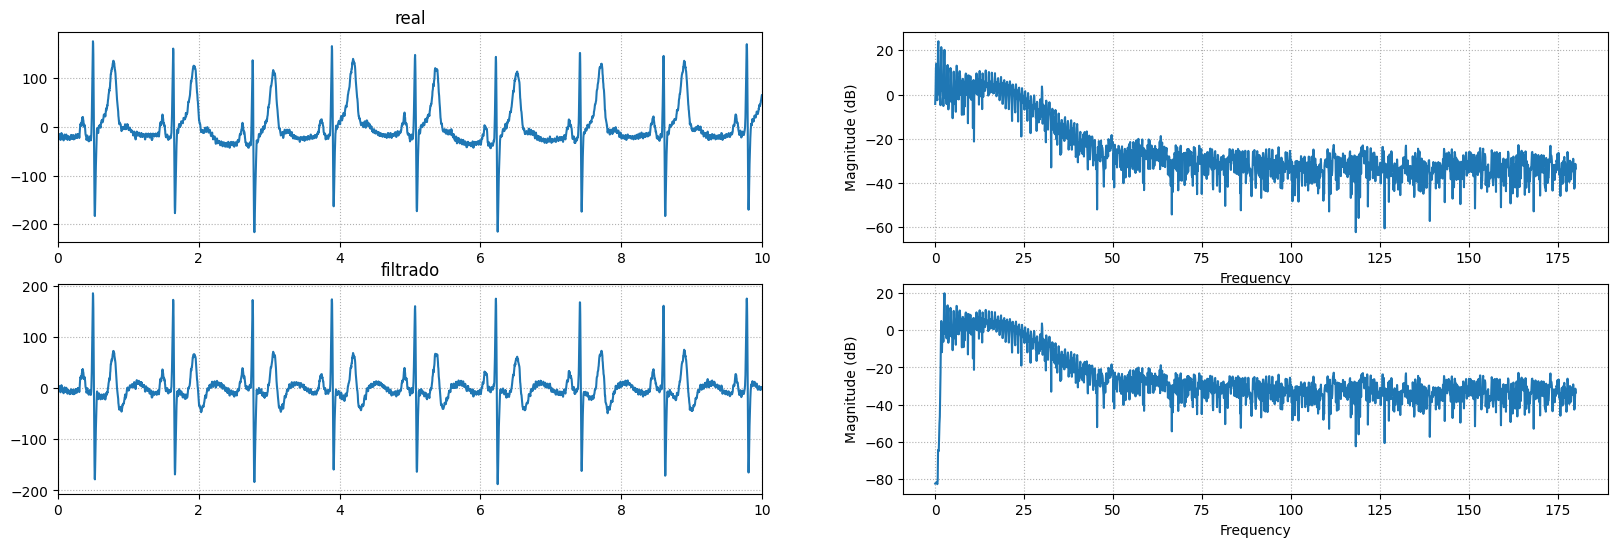

In [113]:
sos = signal.butter(6, 2,
                    btype='high',
                    fs=fs,
                    output='sos')

y = signal.sosfiltfilt(sos, nsr)

plt.figure(figsize=(20,6))

plt.subplot(2,2,1)
plt.title("real")
plt.plot(t,nsr)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,2)
plt.magnitude_spectrum(nsr, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.subplot(2,2,3)
plt.title("filtrado")
plt.plot(t,y)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,4)
plt.magnitude_spectrum(y, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.show()

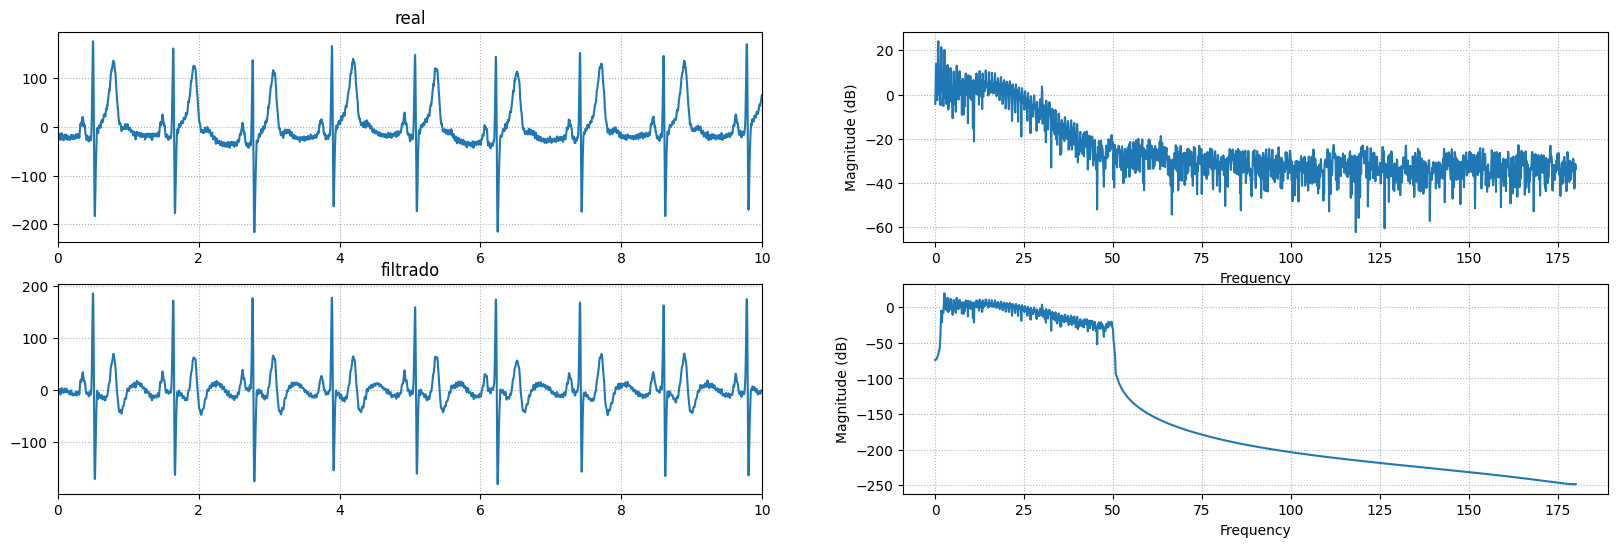

In [118]:
fs = 360

b = signal.firwin(numtaps=801, cutoff=[2,50], window='hann', fs=360,  pass_zero=False)

y = signal.filtfilt(b, 1, nsr)

plt.figure(figsize=(20,6))

plt.subplot(2,2,1)
plt.title("real")
plt.plot(t,nsr)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,2)
plt.magnitude_spectrum(nsr, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.subplot(2,2,3)
plt.title("filtrado")
plt.plot(t,y)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,4)
plt.magnitude_spectrum(y, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.show()

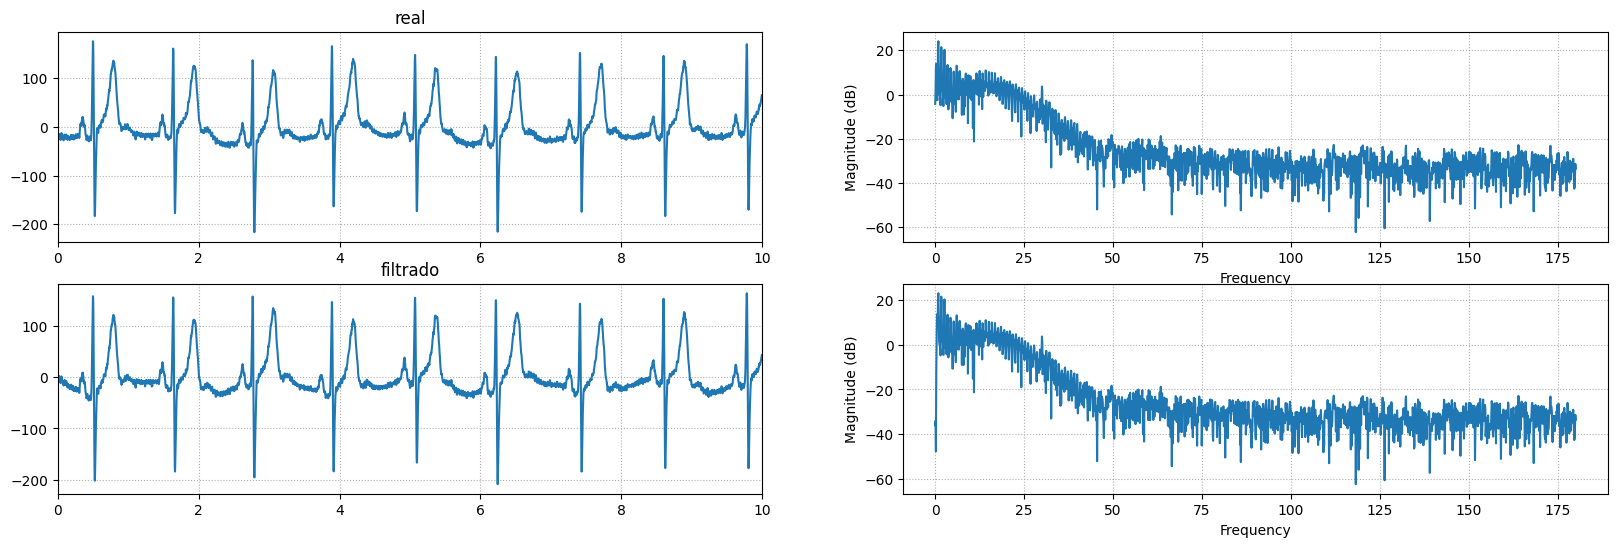

In [138]:
import pywt
import numpy as np

def dwt_baseline_remove(x, wavelet='db6', level=8):
    coeffs = pywt.wavedec(x, wavelet, level=level)
    # baseline = solo aproximación (A_level), anula detalles
    baseline_coeffs = [coeffs[0]] + [np.zeros_like(c) for c in coeffs[1:]]
    baseline = pywt.waverec(baseline_coeffs, wavelet)[:len(x)]
    y = x - baseline
    return y, baseline

y, baseline = dwt_baseline_remove(nsr, wavelet='db6', level=8)

plt.figure(figsize=(20,6))

plt.subplot(2,2,1)
plt.title("real")
plt.plot(t,nsr)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,2)
plt.magnitude_spectrum(nsr, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.subplot(2,2,3)
plt.title("filtrado")
plt.plot(t,y)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,4)
plt.magnitude_spectrum(y, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.show()

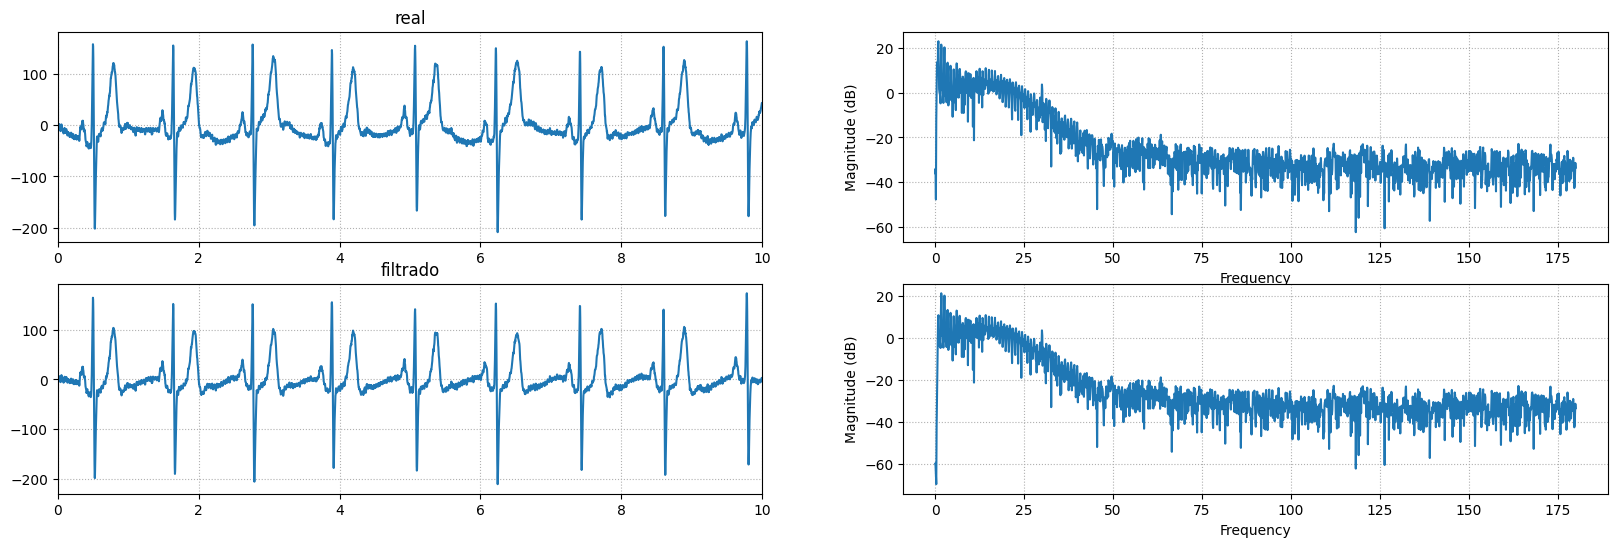

In [147]:
sos = signal.butter(4,1.,
                    btype='high',
                    fs=fs,
                    output='sos')

yy = signal.sosfiltfilt(sos, y)

plt.figure(figsize=(20,6))

plt.subplot(2,2,1)
plt.title("real")
plt.plot(t,y)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,2)
plt.magnitude_spectrum(y, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.subplot(2,2,3)
plt.title("filtrado")
plt.plot(t,yy)
plt.grid(ls=":")
plt.xlim(0,10)

plt.subplot(2,2,4)
plt.magnitude_spectrum(yy, Fs=fs, scale='dB')
plt.grid(ls=":")

plt.show()